In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q einops

In [9]:
# ----------------------------------------------------------------
# 1. PATHS - AUTO-DETECTED
# ----------------------------------------------------------------
import os
from glob import glob

DATASET_ROOT = "/content/drive/MyDrive/Colab Notebooks/Wound/Woundds"

# ---- GT mask folder (contains *_tissue.png or *_tissue_mask.png) ----
def find_gt_folder(root):
    """Find folder with tissue masks (values 0-3)."""
    candidates = []
    for r, dirs, files in os.walk(root):
        # Look for *_tissue.png or *_tissue_mask.png
        n_tissue = len([f for f in files if f.endswith("_tissue.png")])
        n_tissuemask = len([f for f in files if f.endswith("_tissue_mask.png")])
        total = n_tissue + n_tissuemask
        if total > 50:
            pattern = "_tissue.png" if n_tissue > n_tissuemask else "_tissue_mask.png"
            candidates.append((r, total, pattern))
    if not candidates:
        return None, 0, None
    return max(candidates, key=lambda x: x[1])


# ---- PRED mask folder (contains *_pred.png or *_pred_mask.png) ----
def find_pred_folder(root):
    """Find folder with predicted masks."""
    candidates = []
    for r, dirs, files in os.walk(root):
        n_pred = len([f for f in files if f.endswith("_pred.png")])
        n_predmask = len([f for f in files if f.endswith("_pred_mask.png")])
        total = n_pred + n_predmask
        if total > 50:
            pattern = "_pred.png" if n_pred > n_predmask else "_pred_mask.png"
            candidates.append((r, total, pattern))
    if not candidates:
        return None, 0, None
    return max(candidates, key=lambda x: x[1])


# ---- Execute auto-detection ----
MASK_DIR, n_gt, GT_PATTERN = find_gt_folder(DATASET_ROOT)
PRED_DIR, n_pred, PRED_PATTERN = find_pred_folder(DATASET_ROOT)

print("=" * 70)
print("FOLDER AUTO-DETECTION")
print("=" * 70)
print(f"GT folder   : {MASK_DIR}   ({n_gt} files, pattern: *{GT_PATTERN})")
print(f"PRED folder : {PRED_DIR}   ({n_pred} files, pattern: *{PRED_PATTERN})")

# Embeddings folder (optional)
EMB_CANDIDATES = []
for r, dirs, files in os.walk(DATASET_ROOT):
    if "embed" in r.lower():
        n_npy = len([f for f in files if f.endswith(".npy")])
        if n_npy > 50:
            EMB_CANDIDATES.append((r, n_npy))
if EMB_CANDIDATES:
    EMB_DIR, n_emb = max(EMB_CANDIDATES, key=lambda x: x[1])
    print(f"EMB folder  : {EMB_DIR}   ({n_emb} files)")
else:
    EMB_DIR = None
    print(f"EMB folder  : (not found)")

# Output folder
OUTPUT_DIR = os.path.join(DATASET_ROOT, "STAGEWISE", "VisionMamba_Results", "Evaluation")
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"OUTPUT dir  : {OUTPUT_DIR}")

# ----------------------------------------------------------------
# 2. DISCOVER VALID TEST CASES
# ----------------------------------------------------------------
def get_all_valid_cases():
    """Match GT and PRED by case_id (strip suffixes)."""
    # Build sets of case IDs
    gt_cases = set()
    for f in os.listdir(MASK_DIR):
        if f.endswith(GT_PATTERN):
            case = f.replace(GT_PATTERN, "")
            gt_cases.add(case)

    pred_cases = set()
    for f in os.listdir(PRED_DIR):
        if f.endswith(PRED_PATTERN):
            case = f.replace(PRED_PATTERN, "")
            pred_cases.add(case)

    common = sorted(gt_cases & pred_cases)
    return common


test_cases = get_all_valid_cases()
print(f"\nGT cases   : {len(gt_cases) if 'gt_cases' in dir() else 'N/A'}")
print(f"Found {len(test_cases)} valid test cases with both GT and Prediction")

if len(test_cases) == 0:
    print("\n⚠️  NO MATCHING CASES FOUND. Diagnostics:")
    print(f"  Mask dir contents (first 5):")
    for f in sorted(os.listdir(MASK_DIR))[:5]:
        print(f"    {f}")
    print(f"  Pred dir contents (first 5):")
    for f in sorted(os.listdir(PRED_DIR))[:5]:
        print(f"    {f}")
    raise ValueError("No common cases between GT and PRED folders.")

print(f"\nSample cases: {test_cases[:10]}")

if len(test_cases) < 2:
    raise ValueError("Need at least 2 test cases to compute standard deviation.")

FOLDER AUTO-DETECTION
GT folder   : /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/Mask   (4518 files, pattern: *_tissue.png)
PRED folder : /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/pred_masks   (348 files, pattern: *_pred.png)
EMB folder  : /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/embeddings   (348 files)
OUTPUT dir  : /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation

GT cases   : N/A
Found 348 valid test cases with both GT and Prediction

Sample cases: ['Abrasions_019', 'Abrasions_021', 'Abrasions_024', 'Abrasions_026', 'Abrasions_030', 'Abrasions_031', 'Abrasions_033', 'Abrasions_046', 'Abrasions_049', 'Abrasions_052']


In [10]:
# ----------------------------------------------------------------
# 1. PATHS (CORRECTED — based on auto-detection results)
# ----------------------------------------------------------------
DATASET_ROOT = "/content/drive/MyDrive/Colab Notebooks/Wound/Woundds"

# GT tissue masks: 4518 files at DATASET_ROOT/Mask/
MASK_DIR     = os.path.join(DATASET_ROOT, "Mask")

# Predictions: 348 files at DATASET_ROOT/STAGEWISE/pred_masks/
PRED_DIR     = os.path.join(DATASET_ROOT, "STAGEWISE", "pred_masks")

# Embeddings: 348 files at DATASET_ROOT/STAGEWISE/embeddings/
EMB_DIR      = os.path.join(DATASET_ROOT, "STAGEWISE", "embeddings")

# Output folder
OUTPUT_DIR   = os.path.join(DATASET_ROOT, "STAGEWISE", "VisionMamba_Results", "Evaluation")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Filename suffixes (from auto-detection)
GT_SUFFIX    = "_tissue.png"    # e.g. Abrasions_019_tissue.png
PRED_SUFFIX  = "_pred.png"      # e.g. Abrasions_019_pred.png

CLASS_NAMES = ["Background", "Granulation", "Slough", "Necrosis"]
COLORS = ["#333333", "#E41A1C", "#FF7F00", "#4DAF4A"]

print("=" * 70)
print("PATHS CONFIGURED")
print("=" * 70)
print(f"MASK_DIR   : {MASK_DIR}")
print(f"PRED_DIR   : {PRED_DIR}")
print(f"EMB_DIR    : {EMB_DIR}")
print(f"OUTPUT_DIR : {OUTPUT_DIR}")
print(f"GT suffix  : *{GT_SUFFIX}")
print(f"PRED suffix: *{PRED_SUFFIX}")

PATHS CONFIGURED
MASK_DIR   : /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/Mask
PRED_DIR   : /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/pred_masks
EMB_DIR    : /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/embeddings
OUTPUT_DIR : /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation
GT suffix  : *_tissue.png
PRED suffix: *_pred.png



Evaluating all test cases...


100%|██████████| 348/348 [11:39<00:00,  2.01s/it]



✓ Full results saved: /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation/all_test_cases_metrics_WTP_WFV.csv
               Case  Dice_Background  Dice_Granulation  Dice_Slough  Dice_Necrosis  IoU_Background  IoU_Granulation  IoU_Slough  IoU_Necrosis  WTP_Background  WTP_Granulation  WTP_Slough  WTP_Necrosis  WFV_Norm  WFV_Mean  WFV_Std  mDice_Foreground  mIoU_Foreground
      Abrasions_019           0.7695            0.5792       0.2736         0.7041          0.6253           0.4076      0.1585        0.5434         30.9998          39.1479      3.6987       26.1536    3.0879   -0.0036   0.2228            0.5190           0.3698
      Abrasions_021           0.0000            0.2431       0.6867         0.7617          0.0000           0.1384      0.5229        0.6151          0.0000           6.7200     63.0554       30.2246    3.4761   -0.0009   0.2509            0.5638           0.4255
      Abrasions_024           0.0000            0.000

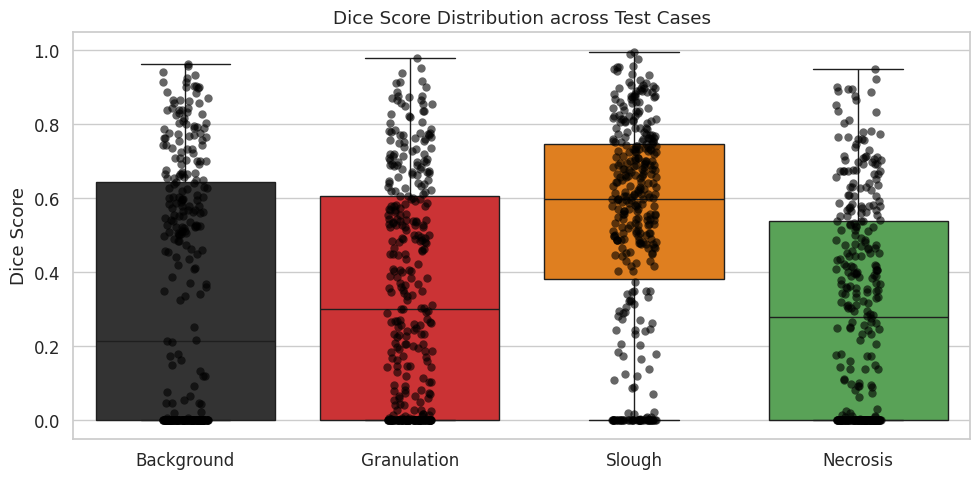

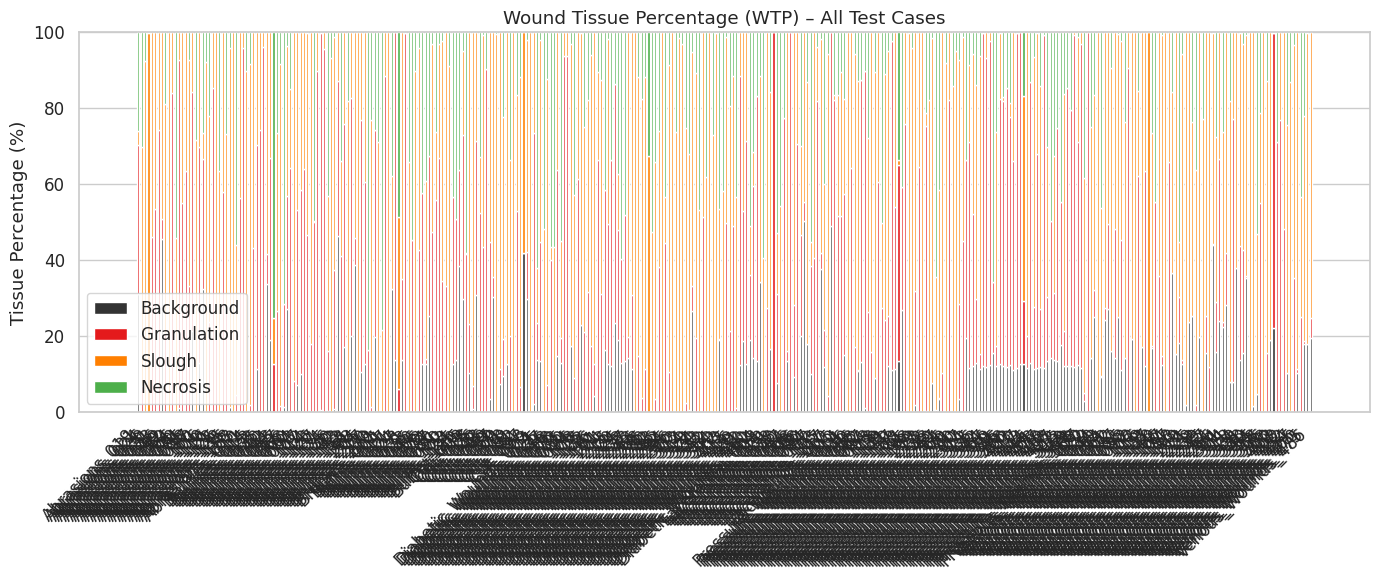

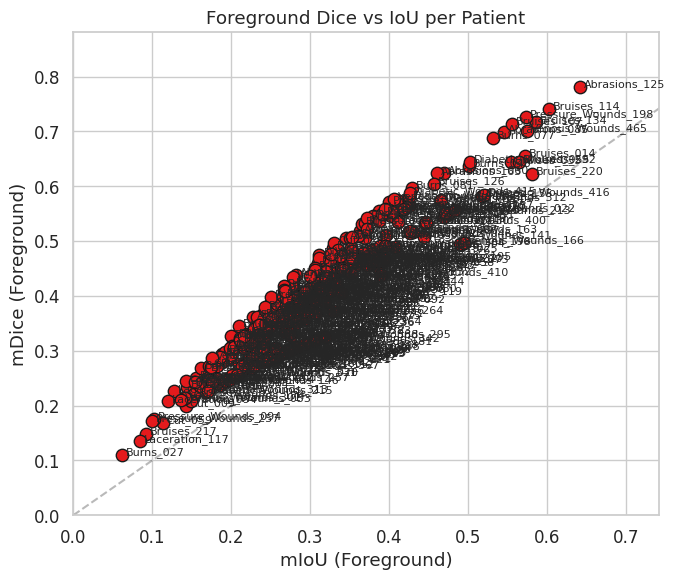

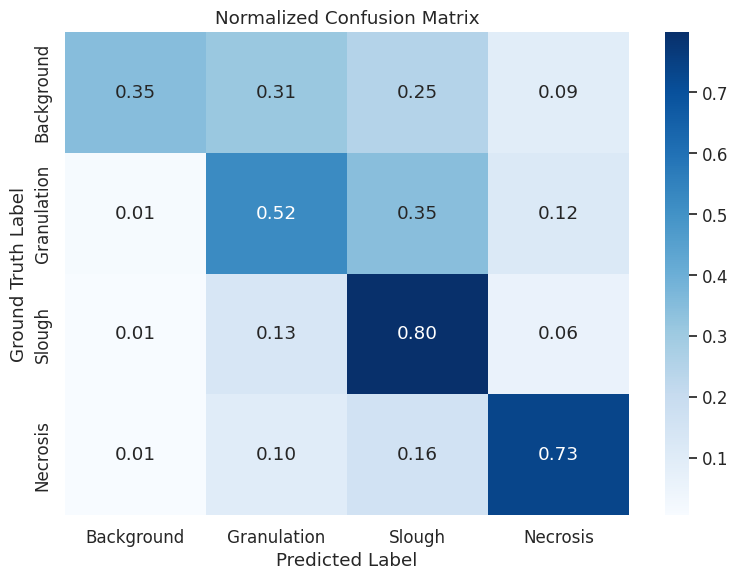

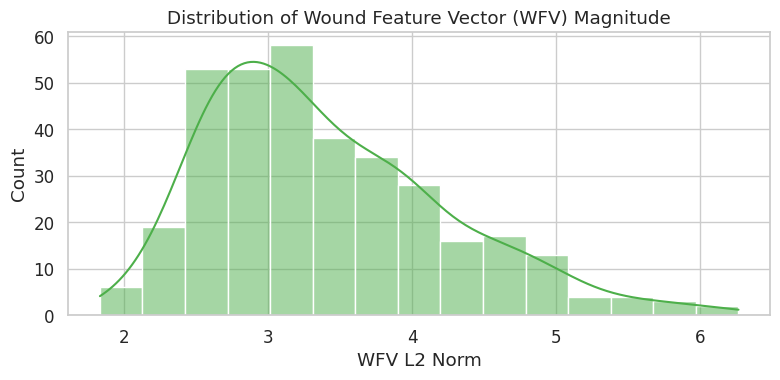


ALL OUTPUTS SAVED IN:
/content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation
Files created:
  • all_test_cases_metrics_WTP_WFV.csv
  • summary_metrics.csv
  • dice_boxplot.png
  • WTP_stacked_bar.png
  • dice_vs_iou_scatter.png
  • confusion_matrix.png
  • WFV_norm_distribution.png


In [12]:
records = []
all_gt = []
all_pred = []

print("\nEvaluating all test cases...")

for case in tqdm(test_cases):
    gt_path   = os.path.join(MASK_DIR, f"{case}{GT_SUFFIX}")
    pred_path = os.path.join(PRED_DIR, f"{case}{PRED_SUFFIX}")
    emb_path  = os.path.join(EMB_DIR, f"{case}_wfv.npy")

    gt   = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    pred = cv2.imread(pred_path, cv2.IMREAD_GRAYSCALE)

    if pred.shape != gt.shape:
        pred = cv2.resize(pred, (gt.shape[1], gt.shape[0]), interpolation=cv2.INTER_NEAREST)

    # ----- Dice & IoU -----
    dices, ious = dice_iou_per_class(gt, pred)

    # ----- WTP from Prediction (formula from diagram) -----
    total_pixels = pred.size
    wtp = {}
    for c, name in enumerate(CLASS_NAMES):
        wtp[name] = (pred == c).sum() / total_pixels * 100.0

    # ----- WFV -----
    if os.path.exists(emb_path):
        wfv = np.load(emb_path)
        wfv_norm = np.linalg.norm(wfv)
        wfv_mean = float(wfv.mean())
        wfv_std  = float(wfv.std())
    else:
        wfv = None
        wfv_norm = wfv_mean = wfv_std = np.nan

    # ----- Store -----
    rec = {
        "Case": case,
        "Dice_Background": dices[0],
        "Dice_Granulation": dices[1],
        "Dice_Slough": dices[2],
        "Dice_Necrosis": dices[3],
        "IoU_Background": ious[0],
        "IoU_Granulation": ious[1],
        "IoU_Slough": ious[2],
        "IoU_Necrosis": ious[3],
        "WTP_Background": wtp["Background"],
        "WTP_Granulation": wtp["Granulation"],
        "WTP_Slough": wtp["Slough"],
        "WTP_Necrosis": wtp["Necrosis"],
        "WFV_Norm": wfv_norm,
        "WFV_Mean": wfv_mean,
        "WFV_Std": wfv_std
    }
    # Foreground means
    fg_dice = [d for d in dices[1:] if not np.isnan(d)]
    fg_iou  = [i for i in ious[1:] if not np.isnan(i)]
    rec["mDice_Foreground"] = np.nanmean(fg_dice) if fg_dice else np.nan
    rec["mIoU_Foreground"]  = np.nanmean(fg_iou) if fg_iou else np.nan

    records.append(rec)
    all_gt.append(gt.flatten())
    all_pred.append(pred.flatten())

df = pd.DataFrame(records)

# Save full per-patient table
full_csv = os.path.join(OUTPUT_DIR, "all_test_cases_metrics_WTP_WFV.csv")
df.to_csv(full_csv, index=False)
print(f"\n✓ Full results saved: {full_csv}")
print(df.round(4).to_string(index=False))

# ----------------------------------------------------------------
# 5. Summary Table (Mean ± Std) – Fixed
# ----------------------------------------------------------------
summary_rows = []
for name in CLASS_NAMES:
    m_d, s_d = safe_mean_std(df[f"Dice_{name}"])
    m_i, s_i = safe_mean_std(df[f"IoU_{name}"])
    summary_rows.append({
        "Class": name,
        "Dice (Mean ± Std)": f"{m_d:.4f} ± {s_d:.4f}",
        "IoU (Mean ± Std)": f"{m_i:.4f} ± {s_i:.4f}",
        "WTP Mean (%)": f"{df[f'WTP_{name}'].mean():.2f}"
    })

m_fd, s_fd = safe_mean_std(df["mDice_Foreground"])
m_fi, s_fi = safe_mean_std(df["mIoU_Foreground"])
summary_rows.append({
    "Class": "Foreground Mean",
    "Dice (Mean ± Std)": f"{m_fd:.4f} ± {s_fd:.4f}",
    "IoU (Mean ± Std)": f"{m_fi:.4f} ± {s_fi:.4f}",
    "WTP Mean (%)": "-"
})

df_summary = pd.DataFrame(summary_rows)
print("\n" + "="*80)
print("JOURNAL SUMMARY TABLE (Std fixed)")
print("="*80)
print(df_summary.to_string(index=False))

df_summary.to_csv(os.path.join(OUTPUT_DIR, "summary_metrics.csv"), index=False)

# ----------------------------------------------------------------
# 6. ADVANCED GRAPHS
# ----------------------------------------------------------------
sns.set_theme(style="whitegrid", font_scale=1.1)

# 6.1 Per-class Dice distribution
fig, ax = plt.subplots(figsize=(10, 5))
dice_data = df[["Dice_Background", "Dice_Granulation", "Dice_Slough", "Dice_Necrosis"]]
dice_data.columns = CLASS_NAMES
sns.boxplot(data=dice_data, palette=COLORS, ax=ax)
sns.stripplot(data=dice_data, color="black", alpha=0.6, size=6, ax=ax)
ax.set_ylabel("Dice Score")
ax.set_title("Dice Score Distribution across Test Cases")
ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "dice_boxplot.png"), dpi=300)
plt.show()

# 6.2 WTP comparison (stacked bar for each patient)
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(df))
width = 0.6
bottom = np.zeros(len(df))
for i, name in enumerate(CLASS_NAMES):
    vals = df[f"WTP_{name}"].values
    ax.bar(x, vals, width, label=name, bottom=bottom, color=COLORS[i])
    bottom += vals
ax.set_xticks(x)
ax.set_xticklabels(df["Case"], rotation=45, ha="right")
ax.set_ylabel("Tissue Percentage (%)")
ax.set_title("Wound Tissue Percentage (WTP) – All Test Cases")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "WTP_stacked_bar.png"), dpi=300)
plt.show()

# 6.3 Foreground Dice vs IoU scatter
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df["mIoU_Foreground"], df["mDice_Foreground"], s=80, c="#E41A1C", edgecolor="k")
for i, row in df.iterrows():
    ax.text(row["mIoU_Foreground"]+0.005, row["mDice_Foreground"], row["Case"], fontsize=8)
ax.set_xlabel("mIoU (Foreground)")
ax.set_ylabel("mDice (Foreground)")
ax.set_title("Foreground Dice vs IoU per Patient")
ax.plot([0,1], [0,1], "k--", alpha=0.3)
ax.set_xlim(0, max(0.5, df["mIoU_Foreground"].max()+0.1))
ax.set_ylim(0, max(0.5, df["mDice_Foreground"].max()+0.1))
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "dice_vs_iou_scatter.png"), dpi=300)
plt.show()

# 6.4 Confusion Matrix
cm = confusion_matrix(np.concatenate(all_gt), np.concatenate(all_pred), labels=[0,1,2,3])
cm_norm = cm.astype(float) / (cm.sum(axis=1)[:, None] + 1e-8)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Ground Truth Label")
ax.set_title("Normalized Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=300)
plt.show()

# 6.5 WFV magnitude distribution
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["WFV_Norm"].dropna(), bins=15, kde=True, color="#4DAF4A", ax=ax)
ax.set_xlabel("WFV L2 Norm")
ax.set_title("Distribution of Wound Feature Vector (WFV) Magnitude")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "WFV_norm_distribution.png"), dpi=300)
plt.show()

print("\n" + "="*80)
print("ALL OUTPUTS SAVED IN:")
print(OUTPUT_DIR)
print("="*80)
print("Files created:")
print("  • all_test_cases_metrics_WTP_WFV.csv")
print("  • summary_metrics.csv")
print("  • dice_boxplot.png")
print("  • WTP_stacked_bar.png")
print("  • dice_vs_iou_scatter.png")
print("  • confusion_matrix.png")
print("  • WFV_norm_distribution.png")

Evaluating segmentation performance...



100%|██████████| 7/7 [00:00<00:00, 454.88it/s]

  Skipping case_5 – file missing
  Skipping case_8 – file missing
  Skipping case_13 – file missing
  Skipping case_33 – file missing
  Skipping case_42 – file missing
  Skipping case_46 – file missing

✓ Per-patient metrics saved: /content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results_new/segmentation_metrics_per_patient.csv

JOURNAL-READY SUMMARY TABLE
          Class Dice (Mean ± Std) IoU (Mean ± Std) Precision Recall
     Background      0.5769 ± nan     0.4054 ± nan    0.4487 0.8079
    Granulation      0.1493 ± nan     0.0807 ± nan    0.1482 0.1504
         Slough      0.3165 ± nan     0.1880 ± nan    0.5382 0.2242
       Necrosis      0.0000 ± nan     0.0000 ± nan    0.0000 0.0000
Foreground Mean      0.1553 ± nan     0.0896 ± nan         -      -

✓ Summary table saved: /content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results_new/segmentation_metrics_summary.csv


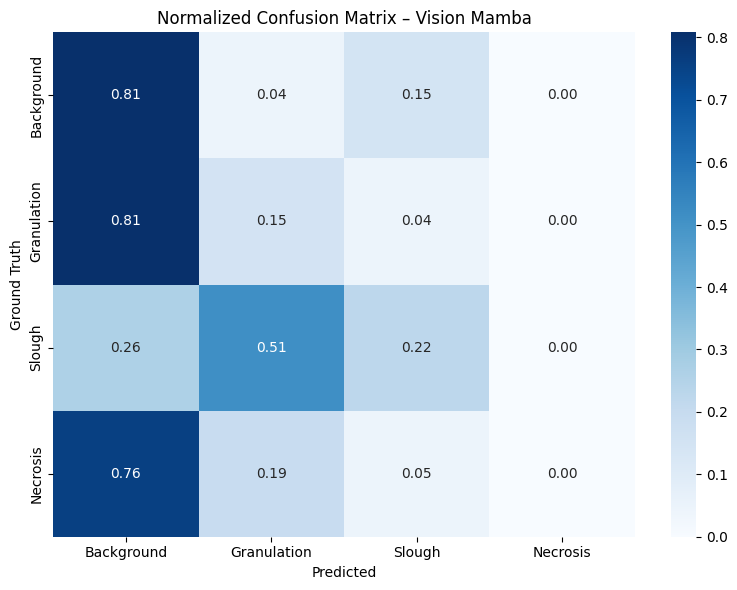

✓ Confusion matrix saved: /content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results_new/confusion_matrix.png

FILES READY FOR JOURNAL PAPER
1. /content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results_new/segmentation_metrics_per_patient.csv
2. /content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results_new/segmentation_metrics_summary.csv
3. /content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results_new/confusion_matrix.png
4. training_curve.png (from training)
5. WTP_WFV_results.csv


In [ ]:
# ================================================================
# Journal-Ready Evaluation Metrics
# Dice, IoU, Precision, Recall, Class-wise scores
# ================================================================

import os
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ----------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------
MASK_DIR     = "/content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/Mask"
PRED_DIR     = "/content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results/segmentation_masks"
OUTPUT_DIR   = "/content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results_new"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_NAMES = ["Background", "Granulation", "Slough", "Necrosis"]
NUM_CLASSES = 4

# ----------------------------------------------------------------
# Metric functions
# ----------------------------------------------------------------
def calculate_dice_iou(y_true, y_pred, num_classes=4):
    """Compute per-class and mean Dice & IoU"""
    dice_list, iou_list = [], []

    for c in range(num_classes):
        gt = (y_true == c)
        pr = (y_pred == c)

        intersection = np.logical_and(gt, pr).sum()
        union = np.logical_or(gt, pr).sum()
        gt_sum = gt.sum()
        pr_sum = pr.sum()

        # Dice
        if (gt_sum + pr_sum) == 0:
            dice = np.nan          # class absent in both
        else:
            dice = (2.0 * intersection) / (gt_sum + pr_sum + 1e-8)

        # IoU
        if union == 0:
            iou = np.nan
        else:
            iou = intersection / (union + 1e-8)

        dice_list.append(dice)
        iou_list.append(iou)

    return dice_list, iou_list


def calculate_precision_recall(y_true, y_pred, num_classes=4):
    prec_list, rec_list = [], []
    for c in range(num_classes):
        gt = (y_true == c)
        pr = (y_pred == c)

        tp = np.logical_and(gt, pr).sum()
        fp = np.logical_and(~gt, pr).sum()
        fn = np.logical_and(gt, ~pr).sum()

        prec = tp / (tp + fp + 1e-8)
        rec  = tp / (tp + fn + 1e-8)

        prec_list.append(prec)
        rec_list.append(rec)
    return prec_list, rec_list


# ----------------------------------------------------------------
# Evaluate all test patients
# ----------------------------------------------------------------
def evaluate_all_patients(test_cases):
    records = []
    all_true = []
    all_pred = []

    print("Evaluating segmentation performance...\n")

    for case in tqdm(test_cases):
        gt_path   = os.path.join(MASK_DIR, f"{case}_tissue_mask.png")
        pred_path = os.path.join(PRED_DIR, f"{case}_pred_mask.png")

        if not (os.path.exists(gt_path) and os.path.exists(pred_path)):
            print(f"  Skipping {case} – file missing")
            continue

        gt   = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
        pred = cv2.imread(pred_path, cv2.IMREAD_GRAYSCALE)

        # Resize prediction to GT size if needed
        if pred.shape != gt.shape:
            pred = cv2.resize(pred, (gt.shape[1], gt.shape[0]), interpolation=cv2.INTER_NEAREST)

        dice, iou = calculate_dice_iou(gt, pred)
        prec, rec = calculate_precision_recall(gt, pred)

        record = {"Case": case}
        for i, name in enumerate(CLASS_NAMES):
            record[f"Dice_{name}"] = dice[i]
            record[f"IoU_{name}"]  = iou[i]
            record[f"Precision_{name}"] = prec[i]
            record[f"Recall_{name}"] = rec[i]

        # Mean over foreground classes (ignore background if desired)
        fg_dice = [d for d in dice[1:] if not np.isnan(d)]
        fg_iou  = [i for i in iou[1:] if not np.isnan(i)]
        record["mDice_Foreground"] = np.nanmean(fg_dice) if fg_dice else np.nan
        record["mIoU_Foreground"]  = np.nanmean(fg_iou) if fg_iou else np.nan
        record["mDice_All"] = np.nanmean(dice)
        record["mIoU_All"]  = np.nanmean(iou)

        records.append(record)
        all_true.append(gt.flatten())
        all_pred.append(pred.flatten())

    df = pd.DataFrame(records)
    return df, np.concatenate(all_true), np.concatenate(all_pred)


# ----------------------------------------------------------------
# Main evaluation
# ----------------------------------------------------------------
# List your test cases here (from the split you used)
# Example:
test_cases = [f"case_{i}" for i in [5, 8, 13, 33, 34, 42, 46]]  # replace with your actual test list

df_metrics, y_true, y_pred = evaluate_all_patients(test_cases)

# Save detailed per-patient metrics
csv_path = os.path.join(OUTPUT_DIR, "segmentation_metrics_per_patient.csv")
df_metrics.to_csv(csv_path, index=False)
print(f"\n✓ Per-patient metrics saved: {csv_path}")

# ----------------------------------------------------------------
# Summary Table (Journal style)
# ----------------------------------------------------------------
summary_data = []
for name in CLASS_NAMES:
    summary_data.append({
        "Class": name,
        "Dice (Mean ± Std)": f"{df_metrics[f'Dice_{name}'].mean():.4f} ± {df_metrics[f'Dice_{name}'].std():.4f}",
        "IoU (Mean ± Std)":  f"{df_metrics[f'IoU_{name}'].mean():.4f} ± {df_metrics[f'IoU_{name}'].std():.4f}",
        "Precision": f"{df_metrics[f'Precision_{name}'].mean():.4f}",
        "Recall": f"{df_metrics[f'Recall_{name}'].mean():.4f}"
    })

summary_data.append({
    "Class": "Foreground Mean",
    "Dice (Mean ± Std)": f"{df_metrics['mDice_Foreground'].mean():.4f} ± {df_metrics['mDice_Foreground'].std():.4f}",
    "IoU (Mean ± Std)":  f"{df_metrics['mIoU_Foreground'].mean():.4f} ± {df_metrics['mIoU_Foreground'].std():.4f}",
    "Precision": "-",
    "Recall": "-"
})

df_summary = pd.DataFrame(summary_data)
print("\n" + "="*80)
print("JOURNAL-READY SUMMARY TABLE")
print("="*80)
print(df_summary.to_string(index=False))

summary_path = os.path.join(OUTPUT_DIR, "segmentation_metrics_summary.csv")
df_summary.to_csv(summary_path, index=False)
print(f"\n✓ Summary table saved: {summary_path}")

# ----------------------------------------------------------------
# Confusion Matrix
# ----------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2,3])
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-8)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Ground Truth")
ax.set_title("Normalized Confusion Matrix – Vision Mamba")
plt.tight_layout()
cm_path = os.path.join(OUTPUT_DIR, "confusion_matrix.png")
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Confusion matrix saved: {cm_path}")

# ----------------------------------------------------------------
# Final report
# ----------------------------------------------------------------
print("\n" + "="*80)
print("FILES READY FOR JOURNAL PAPER")
print("="*80)
print(f"1. {csv_path}")
print(f"2. {summary_path}")
print(f"3. {cm_path}")
print(f"4. training_curve.png (from training)")
print(f"5. WTP_WFV_results.csv")

✓ Google Drive already mounted
Device: cuda
Patches: 64 | Embed Dim: 64 | Layers: 4

VISION MAMBA – FULL PIPELINE (Real Masks)
Found 46 valid patients with photo + mask
Train: 32 | Val: 7 | Test: 7
Parameters: 0.50 M
Epoch 01/30 | Train Loss: 1.0466 | Val Loss: 1.0108
  ✓ Best model saved
Epoch 02/30 | Train Loss: 0.9765 | Val Loss: 0.9837
  ✓ Best model saved
Epoch 03/30 | Train Loss: 0.9458 | Val Loss: 0.9524
  ✓ Best model saved
Epoch 04/30 | Train Loss: 0.9326 | Val Loss: 0.9613
Epoch 05/30 | Train Loss: 0.9120 | Val Loss: 0.9239
  ✓ Best model saved
Epoch 06/30 | Train Loss: 0.8960 | Val Loss: 0.9170
  ✓ Best model saved
Epoch 07/30 | Train Loss: 0.8810 | Val Loss: 0.8754
  ✓ Best model saved
Epoch 08/30 | Train Loss: 0.8872 | Val Loss: 0.8771
Epoch 09/30 | Train Loss: 0.8656 | Val Loss: 0.8506
  ✓ Best model saved
Epoch 10/30 | Train Loss: 0.8574 | Val Loss: 0.8602
Epoch 11/30 | Train Loss: 0.8617 | Val Loss: 0.8469
  ✓ Best model saved
Epoch 12/30 | Train Loss: 0.8559 | Val Loss

Test patients:  14%|█▍        | 1/7 [00:01<00:07,  1.25s/it]

  case_4: Gran=23.6%  Slough=13.8%  Nec=0.0%


Test patients:  29%|██▊       | 2/7 [00:02<00:06,  1.21s/it]

  case_26: Gran=23.3%  Slough=13.7%  Nec=0.0%


...

  case_43: Gran=23.4%  Slough=16.7%  Nec=1.2%


Test patients:  86%|████████▌ | 6/7 [00:07<00:01,  1.19s/it]

  case_9: Gran=2.4%  Slough=10.8%  Nec=86.8%


Test patients: 100%|██████████| 7/7 [00:08<00:00,  1.21s/it]

  case_28: Gran=2.6%  Slough=11.0%  Nec=86.5%

✓ Results table saved: /content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results/WTP_WFV_results.csv


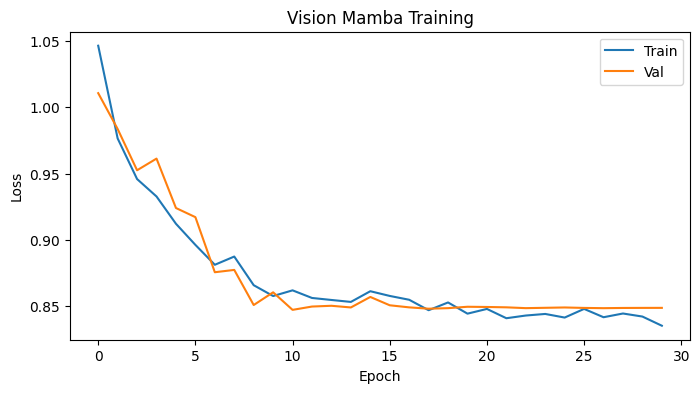


COMPLETED
Output folder: /content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/VisionMamba_Results
  • best_vision_mamba.pth
  • segmentation_masks/
  • embeddings/          (WFV)
  • WTP_WFV_results.csv
  • training_curve.png


In [ ]:
# ================================================================
# Complete Implementation: Bidirectional Selective SSM (Vision Mamba)
# Based on the attached Concept Flow Diagram
# Uses REAL photos + REAL masks (case_1 … case_47)
# Outputs: Segmentation Mask | WTP (Tissue %) | WFV (Deep Embedding)
# ================================================================

import os, gc, json, random
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
from datetime import datetime

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
else:
    print("✓ Google Drive already mounted")

# ----------------------------------------------------------------
# 1. PATHS & CONFIG
# ----------------------------------------------------------------
DATASET_ROOT = "/content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset"
MASK_DIR     = os.path.join(DATASET_ROOT, "Mask")
OUTPUT_ROOT  = os.path.join(DATASET_ROOT, "VisionMamba_Results")
os.makedirs(OUTPUT_ROOT, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_ROOT, "segmentation_masks"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_ROOT, "embeddings"), exist_ok=True)

IMAGE_SIZE   = 128          # training resolution
PATCH_SIZE   = 16
NUM_PATCHES  = (IMAGE_SIZE // PATCH_SIZE) ** 2   # 64
EMBED_DIM    = 64
NUM_LAYERS   = 4
NUM_CLASSES  = 4            # BG, Granulation, Slough, Necrosis
BATCH_SIZE   = 4
EPOCHS       = 30
LR           = 1e-3
DEVICE       = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {DEVICE}")
print(f"Patches: {NUM_PATCHES} | Embed Dim: {EMBED_DIM} | Layers: {NUM_LAYERS}")

# ----------------------------------------------------------------
# 2. DATASET – Real photos + Real tissue masks
# ----------------------------------------------------------------
def find_photo(case_name):
    candidates = [
        os.path.join(DATASET_ROOT, case_name, "day_1", "results", "scene_1", "photo.png"),
        os.path.join(DATASET_ROOT, case_name, "images", "photo.png"),
        os.path.join(DATASET_ROOT, "stage1result", case_name, "images", "photo.png"),
        os.path.join(DATASET_ROOT, case_name, "photo.png"),
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    # recursive fallback
    case_dir = os.path.join(DATASET_ROOT, case_name)
    if os.path.exists(case_dir):
        for r, _, files in os.walk(case_dir):
            for f in files:
                if f.lower() in ["photo.png", "photo.jpg"]:
                    return os.path.join(r, f)
    return None

class WoundMambaDataset(Dataset):
    def __init__(self, case_list, image_size=128, patch_size=16):
        self.cases = case_list
        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2

    def __len__(self):
        return len(self.cases)

    def __getitem__(self, idx):
        case = self.cases[idx]
        photo_path = find_photo(case)
        mask_path  = os.path.join(MASK_DIR, f"{case}_tissue_mask.png")

        # Load image
        img = cv2.imread(photo_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (self.image_size, self.image_size))
        img = img.astype(np.float32) / 255.0

        # Load real tissue mask
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (self.image_size, self.image_size), interpolation=cv2.INTER_NEAREST)
        mask = mask.astype(np.int64)

        # Patchify image → tokens (simple reshape + flatten)
        p = self.patch_size
        patches = img.reshape(self.image_size//p, p, self.image_size//p, p, 3)
        patches = patches.transpose(0, 2, 1, 3, 4).reshape(-1, p*p*3)  # (N, 768)

        return {
            "patches": torch.from_numpy(patches).float(),
            "mask": torch.from_numpy(mask).long(),
            "case": case
        }

# ----------------------------------------------------------------
# 3. MODEL – Bidirectional Selective SSM style (follows diagram)
# ----------------------------------------------------------------
class SSMBlock(nn.Module):
    """Simplified selective SSM block (forward or backward)."""
    def __init__(self, dim, d_state=16):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.in_proj = nn.Linear(dim, dim * 2)
        self.dwconv = nn.Conv1d(dim, dim, kernel_size=3, padding=1, groups=dim)
        self.out_proj = nn.Linear(dim, dim)
        self.A_log = nn.Parameter(torch.randn(dim, d_state) * 0.1)
        self.D = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        # x: (B, N, D)
        residual = x
        x = self.norm(x)
        xz = self.in_proj(x)
        x, z = xz.chunk(2, dim=-1)
        x = self.dwconv(x.transpose(1, 2)).transpose(1, 2)
        x = F.silu(x) * F.silu(z)
        x = self.out_proj(x)
        return residual + x

class BidirectionalMambaBlock(nn.Module):
    """Forward + Backward SSM + Fusion (Equations 1, 1', 3 in diagram)."""
    def __init__(self, dim):
        super().__init__()
        self.forward_ssm  = SSMBlock(dim)
        self.backward_ssm = SSMBlock(dim)
        self.fusion = nn.Sequential(
            nn.Linear(dim * 2, dim),
            nn.GELU(),
            nn.Linear(dim, dim)
        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        # Forward scan
        y_f = self.forward_ssm(x)
        # Backward scan
        y_b = self.backward_ssm(torch.flip(x, dims=[1]))
        y_b = torch.flip(y_b, dims=[1])
        # Fusion (Equation 3)
        y = self.fusion(torch.cat([y_f, y_b], dim=-1))
        return self.norm(x + y)

class VisionMamba(nn.Module):
    """
    Full model following the diagram:
    Patch Embedding → Stacked Bi-Mamba Blocks →
    (Segmentation Decoder + Deep Visual Embedding)
    """
    def __init__(self, in_dim=768, embed_dim=64, depth=4, num_classes=4, num_patches=64):
        super().__init__()
        self.num_patches = num_patches
        self.embed_dim = embed_dim

        # Patch + Linear Embedding + Positional Embedding
        self.patch_embed = nn.Linear(in_dim, embed_dim)
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches, embed_dim) * 0.02)

        # Stacked Mamba Blocks
        self.blocks = nn.ModuleList([BidirectionalMambaBlock(embed_dim) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)

        # --- Segmentation Decoder (upsample to H×W×4) ---
        self.seg_head = nn.Sequential(
            nn.Linear(embed_dim, 256),
            nn.GELU(),
            nn.Linear(256, (IMAGE_SIZE//8) * (IMAGE_SIZE//8) * num_classes)
        )
        self.upsample = nn.Upsample(size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)

        # --- Deep Visual Embedding (WFV) ---
        # Global mean pooling → D-dim vector

    def forward(self, patches):
        # patches: (B, N, 768)
        B = patches.shape[0]
        x = self.patch_embed(patches) + self.pos_embed          # (B, N, D)

        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)                                        # (B, N, D)

        # Deep Visual Embedding (WFV) – Equation in diagram
        wfv = x.mean(dim=1)                                     # (B, D)

        # Segmentation Decoder
        seg = self.seg_head(wfv)                                # (B, 16*16*4)
        seg = seg.view(B, NUM_CLASSES, IMAGE_SIZE//8, IMAGE_SIZE//8)
        seg_logits = self.upsample(seg)                         # (B, 4, H, W)

        return seg_logits, wfv, x

# ----------------------------------------------------------------
# 4. LOSS (CE + Dice) – as recommended in the PDF
# ----------------------------------------------------------------
def dice_loss(pred, target, num_classes=4, smooth=1.0):
    pred = F.softmax(pred, dim=1)
    target_onehot = F.one_hot(target, num_classes).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)
    intersection = torch.sum(pred * target_onehot, dims)
    cardinality = torch.sum(pred + target_onehot, dims)
    dice = (2. * intersection + smooth) / (cardinality + smooth)
    return 1 - dice.mean()

def combined_loss(pred, target):
    ce = F.cross_entropy(pred, target)
    dl = dice_loss(pred, target)
    return 0.5 * ce + 0.5 * dl

# ----------------------------------------------------------------
# 5. TRAINING
# ----------------------------------------------------------------
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    for batch in loader:
        patches = batch["patches"].to(DEVICE)
        mask    = batch["mask"].to(DEVICE)
        optimizer.zero_grad()
        logits, _, _ = model(patches)
        loss = combined_loss(logits, mask)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0
    for batch in loader:
        patches = batch["patches"].to(DEVICE)
        mask    = batch["mask"].to(DEVICE)
        logits, _, _ = model(patches)
        loss = combined_loss(logits, mask)
        total_loss += loss.item()
    return total_loss / len(loader)

# ----------------------------------------------------------------
# 6. MAIN PIPELINE
# ----------------------------------------------------------------
def main():
    print("\n" + "="*70)
    print("VISION MAMBA – FULL PIPELINE (Real Masks)")
    print("="*70)

    # Discover cases that have both photo and mask
    all_cases = []
    for i in range(1, 48):
        case = f"case_{i}"
        mask_path = os.path.join(MASK_DIR, f"{case}_tissue_mask.png")
        if os.path.exists(mask_path) and find_photo(case) is not None:
            all_cases.append(case)

    print(f"Found {len(all_cases)} valid patients with photo + mask")

    # Patient-level split
    train_cases, temp = train_test_split(all_cases, test_size=0.3, random_state=42)
    val_cases, test_cases = train_test_split(temp, test_size=0.5, random_state=42)
    print(f"Train: {len(train_cases)} | Val: {len(val_cases)} | Test: {len(test_cases)}")

    train_ds = WoundMambaDataset(train_cases)
    val_ds   = WoundMambaDataset(val_cases)
    test_ds  = WoundMambaDataset(test_cases)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    test_loader  = DataLoader(test_ds,  batch_size=1, shuffle=False)

    # Model
    model = VisionMamba(
        in_dim=PATCH_SIZE*PATCH_SIZE*3,
        embed_dim=EMBED_DIM,
        depth=NUM_LAYERS,
        num_classes=NUM_CLASSES,
        num_patches=NUM_PATCHES
    ).to(DEVICE)

    print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    # Training loop
    best_val = float("inf")
    history = {"train": [], "val": []}

    for epoch in range(1, EPOCHS+1):
        tr_loss = train_one_epoch(model, train_loader, optimizer)
        va_loss = evaluate(model, val_loader)
        scheduler.step()
        history["train"].append(tr_loss)
        history["val"].append(va_loss)
        print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f}")

        if va_loss < best_val:
            best_val = va_loss
            torch.save(model.state_dict(), os.path.join(OUTPUT_ROOT, "best_vision_mamba.pth"))
            print("  ✓ Best model saved")

    # ----------------------------------------------------------------
    # 7. INFERENCE ON TEST SET → Segmentation + WTP + WFV
    # ----------------------------------------------------------------
    print("\n" + "="*70)
    print("INFERENCE – Generating Segmentation, WTP, WFV")
    print("="*70)

    model.load_state_dict(torch.load(os.path.join(OUTPUT_ROOT, "best_vision_mamba.pth")))
    model.eval()

    results = []
    tissue_names = ["background", "granulation", "slough", "necrosis"]

    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Test patients"):
            patches = batch["patches"].to(DEVICE)
            case = batch["case"][0]

            logits, wfv, _ = model(patches)
            pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()  # (H,W)
            wfv_np = wfv.squeeze(0).cpu().numpy()                             # (D,)

            # Wound Tissue Percentage (WTP) – formula from diagram
            total = pred_mask.size
            wtp = {}
            for cls_id, name in enumerate(tissue_names):
                wtp[name] = float((pred_mask == cls_id).sum() / total * 100.0)

            # Save segmentation mask
            mask_save = os.path.join(OUTPUT_ROOT, "segmentation_masks", f"{case}_pred_mask.png")
            cv2.imwrite(mask_save, pred_mask.astype(np.uint8))

            # Save WFV
            emb_save = os.path.join(OUTPUT_ROOT, "embeddings", f"{case}_wfv.npy")
            np.save(emb_save, wfv_np)

            results.append({
                "case": case,
                "wtp_background": wtp["background"],
                "wtp_granulation": wtp["granulation"],
                "wtp_slough": wtp["slough"],
                "wtp_necrosis": wtp["necrosis"],
                "wfv_dim": len(wfv_np),
                "mask_path": mask_save,
                "wfv_path": emb_save
            })

            print(f"  {case}: Gran={wtp['granulation']:.1f}%  Slough={wtp['slough']:.1f}%  Nec={wtp['necrosis']:.1f}%")

    # Save results table
    df = pd.DataFrame(results)
    csv_path = os.path.join(OUTPUT_ROOT, "WTP_WFV_results.csv")
    df.to_csv(csv_path, index=False)
    print(f"\n✓ Results table saved: {csv_path}")

    # Plot training curves
    plt.figure(figsize=(8,4))
    plt.plot(history["train"], label="Train")
    plt.plot(history["val"], label="Val")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Vision Mamba Training")
    plt.savefig(os.path.join(OUTPUT_ROOT, "training_curve.png"), dpi=150)
    plt.show()

    print("\n" + "="*70)
    print("COMPLETED")
    print("="*70)
    print(f"Output folder: {OUTPUT_ROOT}")
    print("  • best_vision_mamba.pth")
    print("  • segmentation_masks/")
    print("  • embeddings/          (WFV)")
    print("  • WTP_WFV_results.csv")
    print("  • training_curve.png")

if __name__ == "__main__":
    main()